In [37]:
import re
import os
import numpy as np
import pandas as pd
from tqdm import tqdm
from scipy.io import loadmat
import matplotlib.pyplot as plt

In [2]:
RAW_DATA_PATH = 'dataset/raw/'
PROCESSED_PATH = 'dataset/processed/'
BDR = 'Boundary/'
SOL = 'Solve/'
OP = 'OP/'
IN = "IN/"
OUT = "OUT/"

# 정렬시 사용되는 함수
def sorted_number(file_name):
    file_name = os.path.splitext(file_name)
    return (int(file_name[0].split("_")[0]),int(file_name[0].split("_")[-1]))

# 데이터 로드 및 정렬
bdr = sorted(os.listdir(RAW_DATA_PATH+BDR),key=sorted_number)
sol = sorted(os.listdir(RAW_DATA_PATH+SOL),key=sorted_number)

#### 데이터생성

In [42]:
def save_bdr(datalst):
    '''boundary data 생성 함수'''
    SAVE_PATH = PROCESSED_PATH + BDR
    save_data = []
    for name in datalst:
        data = loadmat(RAW_DATA_PATH+BDR+name)['Boundary']
        save_data.append(data)
    save_data = np.array(save_data)
    np.save(SAVE_PATH+'bdr.npy',save_data)

def save_sol(datalst):
    SAVE_PATH = PROCESSED_PATH + SOL
    ux_data = []
    uy_data = []
    p_data = []
    for name in tqdm(datalst):
        df = pd.read_csv(RAW_DATA_PATH+SOL+name)
        line_len = int(np.sqrt(len(df)))
        ux = df['ux'].values.reshape(line_len,line_len)
        uy = df['uy'].values.reshape(line_len,line_len)
        p = df['p'].values.reshape(line_len,line_len)
        ux_data.append(ux)
        uy_data.append(uy)
        p_data.append(p)
    ux_data = np.array(ux_data)
    uy_data = np.array(uy_data)
    p_data = np.array(p_data)
    np.save(SAVE_PATH+'ux.npy',ux_data)
    np.save(SAVE_PATH+'uy.npy',uy_data)
    np.save(SAVE_PATH+'p.npy',p_data)
    
def save_op(datalst):
    length = len(datalst)
    ux_lst = [i.split("_")[2] for i in datalst]
    uy_lst = [i.split("_")[4] for i in datalst]
    density_lst = [1]*length
    viscosity_lst = [1]*length
    
    # 1(UX),2(UY),3(Density),4(Viscosity)
    special_token = [[1,2,3,4]]*length 
    special_value = [[u,v,d,v] for u,v,d,v in zip(ux_lst,uy_lst,density_lst,viscosity_lst)]
    special_token = np.array(special_token)
    special_value = np.array(special_value)
    special_token = special_token.astype('float32')
    special_value = special_value.astype('float32')
    
    SAVE_PATH = PROCESSED_PATH + OP
    np.save(SAVE_PATH+'special_token.npy',special_token)
    np.save(SAVE_PATH+'special_value.npy',special_value)    

In [43]:
save_bdr(bdr)
save_sol(sol)
save_op(sol)

  0%|          | 0/1991 [00:00<?, ?it/s]

100%|██████████| 1991/1991 [00:05<00:00, 350.35it/s]


#### 데이터 생성확인

In [44]:
xx = np.load(PROCESSED_PATH + BDR + "bdr.npy")
ux = np.load(PROCESSED_PATH + SOL + "ux.npy")
uy = np.load(PROCESSED_PATH + SOL + "uy.npy")
p = np.load(PROCESSED_PATH + SOL + "p.npy")
st = np.load(PROCESSED_PATH + OP + "special_token.npy")
sv = np.load(PROCESSED_PATH + OP + "special_value.npy")

# shape 동일 해야함
print(xx.shape,ux.shape,uy.shape,p.shape,st.shape,sv.shape)

(181, 51, 51) (1991, 51, 51) (1991, 51, 51) (1991, 51, 51) (1991, 4) (1991, 4)


#### 입출력 데이터 생성

- 입력 : bdr, 운전조건, 이전 ux,uy,p
- 출력 : 다음 ux,uy,p

In [45]:
# 하나의 Time-Dependent 시뮬레이션시 몇개의 데이터를 생성했는가?
split_num = int(ux.shape[0]/xx.shape[0]) # 11

In [46]:
# 입력
ux_inputs = []
uy_inputs = []
p_inputs = []
st_inputs = []
sv_inputs = []
bdr_inputs = []

# 출력
ux_outputs = []
uy_outputs = []
p_outputs = []


for idx in range(xx.shape[0]):
    ux_temp = ux[split_num*idx:split_num*(idx+1)]
    uy_temp = uy[split_num*idx:split_num*(idx+1)]
    p_temp = p[split_num*idx:split_num*(idx+1)]
    st_temp = st[split_num*idx:split_num*(idx+1)]
    sv_temp = sv[split_num*idx:split_num*(idx+1)]
    length = len(ux_temp)    
    for i in range(length-1):

        # 입력
        ux_inputs.append(ux_temp[i])
        uy_inputs.append(uy_temp[i])
        p_inputs.append(p_temp[i])
        st_inputs.append(st_temp[i])
        sv_inputs.append(sv_temp[i])
        bdr_inputs.append(xx[idx])
        
        # 출력
        ux_outputs.append(ux_temp[i+1])
        uy_outputs.append(uy_temp[i+1])
        p_outputs.append(p_temp[i+1])

# 입력
ux_inputs = np.array(ux_inputs)
uy_inputs = np.array(uy_inputs)
p_inputs = np.array(p_inputs)
st_inputs = np.array(st_inputs)
sv_inputs = np.array(sv_inputs)
bdr_inputs = np.array(bdr_inputs)

# 출력
uy_outputs = np.array(uy_outputs)
ux_outputs = np.array(ux_outputs)
p_outputs = np.array(p_outputs)

In [47]:
print(ux_inputs.shape)
print(ux_outputs.shape)
print(uy_inputs.shape)
print(uy_outputs.shape)
print(p_inputs.shape)
print(p_outputs.shape)
print(bdr_inputs.shape)
print(st_inputs.shape)
print(sv_inputs.shape)

(1810, 51, 51)
(1810, 51, 51)
(1810, 51, 51)
(1810, 51, 51)
(1810, 51, 51)
(1810, 51, 51)
(1810, 51, 51)
(1810, 4)
(1810, 4)


- 정규화

In [48]:
def min_max_scaling(val):
    max_val = np.max(val)
    min_val = np.min(val)
    return (val-min_val)/(max_val-min_val)

scaled_ux_inputs = min_max_scaling(ux_inputs)
scaled_uy_inputs = min_max_scaling(uy_inputs)
scaled_p_inputs = min_max_scaling(p_inputs)
scaled_bdr_inputs = min_max_scaling(bdr_inputs)
scaled_sv_inputs = min_max_scaling(sv_inputs)
scaled_ux_outputs = min_max_scaling(ux_outputs)
scaled_uy_outputs = min_max_scaling(uy_outputs)
scaled_p_outputs = min_max_scaling(p_outputs)

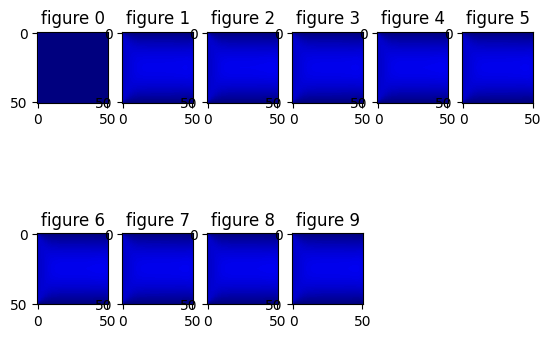

In [57]:
for i in range(0,10):
    plt.subplot(2,6,i+1)
    plt.title(f"figure {i}")
    plt.imshow(scaled_ux_inputs[i],cmap='jet',vmin=0,vmax=1)

- 저장

In [50]:
np.save(PROCESSED_PATH+IN+"special_token.npy",st_inputs)

In [51]:
np.save(PROCESSED_PATH+IN+"ux.npy",scaled_ux_inputs)
np.save(PROCESSED_PATH+IN+"uy.npy",scaled_uy_inputs)
np.save(PROCESSED_PATH+IN+"p.npy",scaled_p_inputs)
np.save(PROCESSED_PATH+IN+"bdr.npy",scaled_bdr_inputs)
np.save(PROCESSED_PATH+IN+"special_value.npy",scaled_sv_inputs)
np.save(PROCESSED_PATH+OUT+"ux.npy",scaled_ux_outputs)
np.save(PROCESSED_PATH+OUT+"uy.npy",scaled_uy_outputs)
np.save(PROCESSED_PATH+OUT+"p.npy",scaled_p_outputs)